## 선형 회귀 예시1

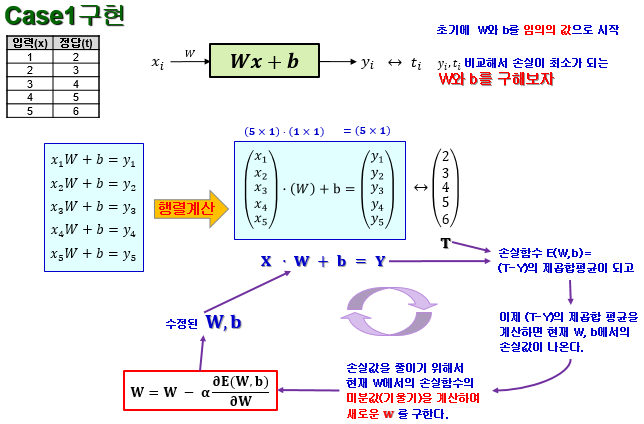

# 기계 학습의 시작
- 개념: 선형 회귀 & 로지스틱 회귀
    - 인간은 환경 내에서 일어나는 변화를 경험하면서 앞으로 발생하는 새로운 상황에 대한 예측이 가능해짐 -> 선형 회귀
        - 물고기 길이와 무게의 관계 
        - 평수와 집값의 관계 
        - 값 X에 대한 Y의 결과 예측
    - 새로운 상황이 과거의 어떤 상황가 같거나 다른지 판별 할 수 있음 -> 로지스틱 회귀(분류) 
        - 동물의 종류를 구분
        - 이진 분류
## Linear Regression
학습 데이터의 예
- 공부 시간에 대한 시험 성적

| 공부 시간(x), 테스트 데이터 | 시험성적(t), 타겟 데이터 | 
|---|---|
| 9 | 74 |
| 14 | 81 |
| 21 | 86 |
| 27 | 90 |
| 32 | 88 |
| 37 | 92 |

    - 위 표를 보면 공부시간에 비례해서 시험 성적도 증가하는 경향이 있음
    - 위 표를 점 그래프로 찍어보고 선을 그어서, 점들의 추이를 잘 나타내는 직선을 통해 주어지지 않은 공부시간(x)에 대한 시험성적(t)를 예측할 수 있음
        - 수학에서 직선은 y = ax + b (a = 기울기, b = y 절편)
        - 머신러닝에서 y = Wx+b로 표현(W = Weight, b = bias)

Linear Regression은
- 주어직 학습 데이터의 추이에 대해 가장 적합한 직전 방정식을 추론해내는 것
    - y = Wx + b에서 가장 적합한 W와 b를 구하는 것
    - 임의의 직선 1, 2, 3, 4에 대해 점들의 추이와 오차가 가장 작은 것은?
- 주어진 데이터 값들과 임의의 각 직선들과의 정확한 수치적 오차 계산이 필요

### Error
- 데이터 값들과 특정 직선(y = Wx + b)과의 오차 계산
    - 오차 = t - y = t - (Wx + b)
        - 모든 x_1, x_2, ...와 실제 성적 t_1, t_2, ...에 대해
        - t_1과 y_1, t_2와 y_2의 차이들의 합
        - 각 오차들은 절댓값을 씌워야 함 (절댓값 or 제곱값)
        - 제곱을 쓰면 포물선 그래프, 작은 차이는 더 작게, 큰 차이는 더 크게, 0에서 연속

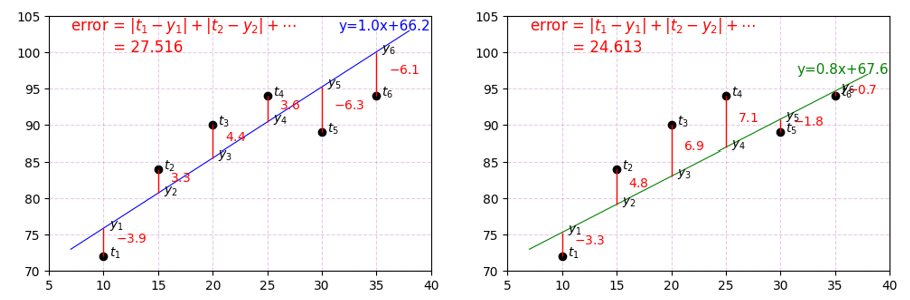
    - 임의의 직선들을 많이 생성하고(W, b 랜덤 생성), 오차를 계산하여 오차가 최소가 되는 직선을 선택
    - 그러나 임의의 직선은 무한대 -> 계산 불가

### Loss Function
- 임의의 한 직선(W, b)을 생성하고, 손실 함수 개념을 이용하여 오차를 줄이는 방향으로 W와 b를 반복적으로 바꿈
    - Loss가 최소일 때의 직선(W, b)이 주어진 데이터에 최적인 직선
    - 즉 최적의 직선을 이용한 예측값은 주어진 데이터 추이에 대해 가장 근사적 추론이 될 수 잇음
- **Loss Function**이란
    - 임의의 한 직선 y = Wx + b에 대해, MSE(Mean Squeare Error)을 손실함수 E(W, b)로 사용 즉,
    $$E(W,b) = \frac 1 n \sum^n_{i=1} [t_i-y_i]^2 = \frac 1 n \sum^n_{i=1} [t_i-(Wx_i+b)]^2$$

- 이와 같이 학습 데이터를 기반으로 손실함수 E(W, b)가 최솟값을 갖도록 하는 (W, b)를 구하는 것이 선형 회귀의 추론 과정이자 최종 목표 -> Gradient Descent

### Gradient Descent Algorithm
- 최소의 손실함수 값을 갖는 (W, b)를 찾는 알고리즘
- 가장 단순한 예시(y = x)를 가정, Wx+b에서 b = 0으로 가정, W를 -2~2를 가정
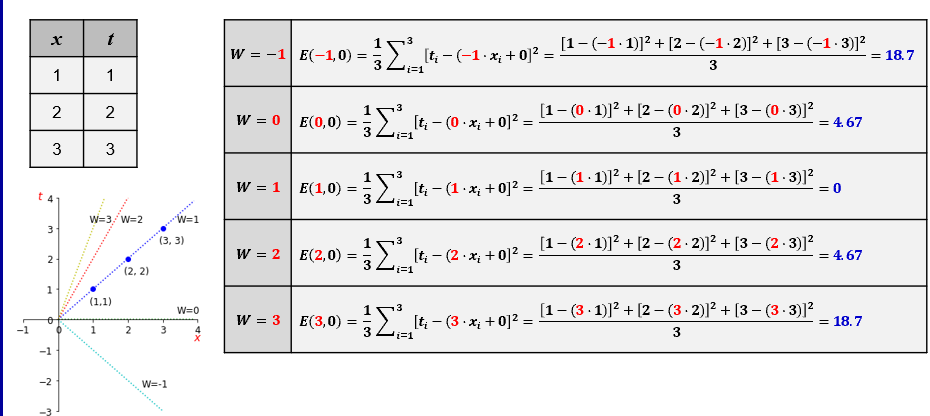
- 손실 함수의 형태
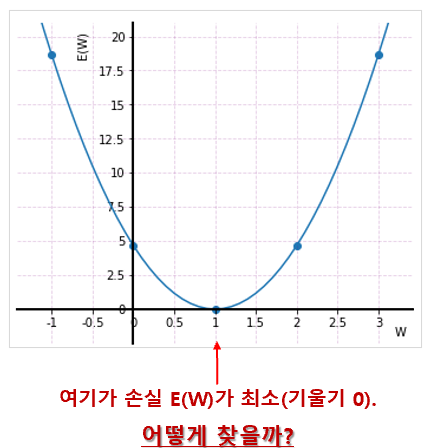
    - 그래프를 그리면 어디가 최소인지 알 수 있음 but 컴퓨터는 모름
    - 손실함수의 기울기가 낮아지는 쪽으로 이동해야 함
    - 이걸 어케 하냐?
- 알고리즘 핵심
    1. 임의의 W를 정함
    2. 그 W에서의 접선의 기울기 계산 (그 W에서의 편미분 값을 구함)
    3. 기울기가 작아지는 쪽으로 W를 변경
    4. 기울기가 더이상 작아지지 않는 지점 찾기
    5. 그 지점의 W에서 E(W)가 최소

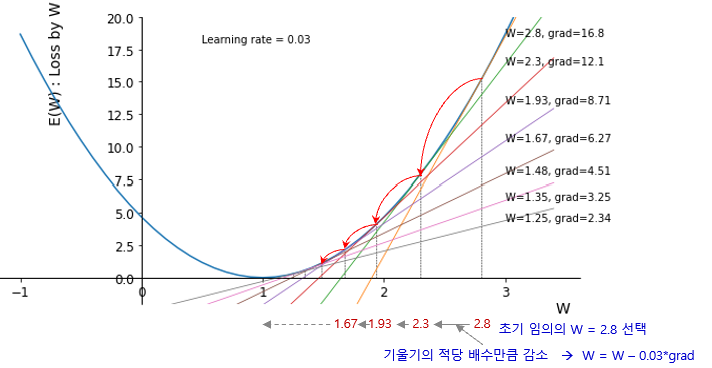 

- 경사하강법으로 (W, b) 구하기
$$W = W - \alpha \frac {\partial E(W, b)} {\partial W}$$
$$b = b - \alpha \frac {\partial E(W, b)} {\partial b}$$
    - W와 b에 대해 각각 편미분
$$\alpha: 학습율$$
- W, b가 감소/증가되는 비율


- 임의의 W에서 W에 대한 편미분 값을 구함
    - 즉, 그 W에서의 기울기
    - 기울기가 양수면 W는 작아짐
    - 기울기가 음수면 W는 커짐

- 행렬을 통해 
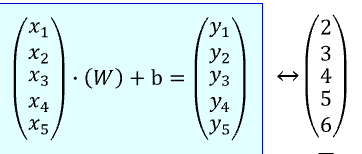
    - 계산값과 실제 값 행렬을 통해 MSE를 구할 수 있음
- Loss를 줄이기 위해 현재 W에서의 손실 함수의 기울기를 계산하여 새로운 W를 구함

#### 구현
**단변수**
- 임의의 W에서의 (E(W, b))의 접선 기울기는
    - (E(W, b))'을 구해서 현재의 W값을 대입
    - 함수식을 구하기가 어려움
$$E' = \frac {\partial E(W, b)} {\partial W} = \lim_{\Delta W -> 0} \frac {E(W + \Delta W, b) - E(W, b)} {\Delta W}$$
- W의 변화량을 굉장히 작게해서 구해도 결과에 큰 차이 없음

**다변수**
- 학습 데이터: 국영수 중간고사 점수와 모의고사 점수
    - 어떤 학생의 국영수 시험 점수로 미래의 모의고사 점수 예측
    - x = 국, 영, 수 
    - t = 모의고사 점수
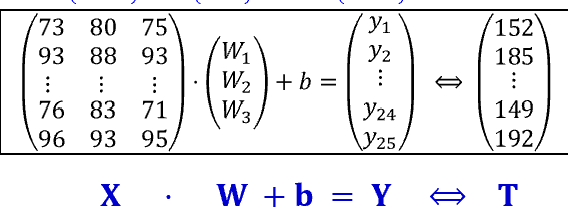

- 각 변수에 대해 다른 가중치가 나옴


In [1]:
import numpy as np

In [2]:
x_data = np.array([1, 2, 3, 4, 5]).reshape(5,1)
t_data = np.array([2, 3, 4, 5, 6]).reshape(5,1)

print("x_data.shape = ", x_data.shape, ", t_data.shape = ", t_data.shape)

W = np.random.rand(1,1)
b = np.random.rand(1)
print("W = ", W, ", W.shape = ", W.shape, ", b = ", b, ", b.shape = ", b.shape)

x_data.shape =  (5, 1) , t_data.shape =  (5, 1)
W =  [[0.58006321]] , W.shape =  (1, 1) , b =  [0.60372015] , b.shape =  (1,)


In [ ]:
def lossFunc():     # E(W, b): 손실함수로서 W나 b값에 따른  x 데이터와 t 레이블의 MSE 리턴
    y = np.dot(x_data, W) + b
    # 내적
    return np.sum((t_data - y)**2) / len(x_data)   # MSE

def numerical_derivative(fn, param):    # 주어진 함수 fn에 대한 W 또는 b에 대한 수치미분
    delta = 1e-4  # 0.0001          # 실제 미분함수를 구하지 않고 특정 W, b의 +/- 0.0001 범위에서 기울기 구함
    grad = np.zeros_like(param)     # 주어진 각 W 또는 b들에 대한 기울기 값 저장

    it = np.nditer(param, flags=['multi_index'], op_flags=['readwrite'])  # 다차원 배열 원소들의 순서참조 지원 함수
    while not it.finished:
        idx = it.multi_index
        temp = param[idx]            # 주어진 W, b값(기울기 대상지점값)을 저장해두고 기울기 계산 후 다시 원상태로 되돌림

        param[idx] = temp + delta
        loss1 = fn()           # W 또는 b의 약간의 증가치(+0.0001)에 대한 손실함수 값
        param[idx] = temp - delta
        loss2 = fn()           # W 또는 b의 약간의 감소치(-0.0001)에 대한 손실함수 값

        grad[idx] = (loss1-loss2) / (2*delta)    # 주어진 W, b의 미세한 구간에서의 손실함수값의 변화량 --> 기울기

        param[idx] = temp            # 기울기값 계산시 사용된 주어진 값의 사용이 끝난뒤 원래 값으로 되돌린다.
        it.iternext()
    return grad


def grad_descent(learning_rate, repeat, outStep):
    global W, b

    print("Initial error value = {:.3f}".format(lossFunc()))
    # print("Initial W = ", W.flatten().round(3))
    # print("Initial b = ", b.round(3))
    for step in range(repeat+1):        # 적당한 횟수만큼 경사하강 반복
        W -= learning_rate * numerical_derivative(lossFunc, W)  # 일급 함수(first-class function) -> 함수 이름을 인자로 사용
        b -= learning_rate * numerical_derivative(lossFunc, b)

        if (step % outStep == 0):       # 경사하강 반복 중간마다 손실값 출력
            print("Step = {:>6d}".format(step), "\tError Value = {:.4f}".format(lossFunc()),
                  "\tW =", W.flatten().round(3), "\tb = ", b.round(3))


# 학습을 마친 후, 임의의 데이터에 대해 예측 함수
def predict(x):         # 입력변수 x : numpy type
    y = np.dot(x,W) + b
    return y

In [11]:
W = np.random.rand(1,1)
b = np.random.rand(1)

learning_rate = 1e-2# 발산하는 경우, 1e-3 ~ 1e-6 등으로 바꾸어서 실행
repeat = 8000
outStep = 500
grad_descent(learning_rate, repeat, outStep)

Initial error value = 5.480
Step =      0 	Error Value = 5.4798 	W = [0.494] 	b =  [0.289]
Step =    500 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   1000 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   1500 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   2000 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   2500 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   3000 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   3500 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   4000 	Error Value = 5.4797 	W = [0.494] 	b =  [0.289]
Step =   4500 	Error Value = 5.4796 	W = [0.494] 	b =  [0.289]
Step =   5000 	Error Value = 5.4796 	W = [0.494] 	b =  [0.289]
Step =   5500 	Error Value = 5.4796 	W = [0.494] 	b =  [0.289]
Step =   6000 	Error Value = 5.4796 	W = [0.494] 	b =  [0.289]
Step =   6500 	Error Value = 5.4796 	W = [0.494] 	b =  [0.289]
Step =   7000 	Error Value = 5.4796 	W = [0.494] 	b =  [0.289]
Step =   7500 	Error Value 

In [12]:
print("W = {}, b = {}".format(W, b))

W = [[0.50616943]], b = [0.29281461]


In [13]:
predict(7)

array([[3.83600064]])

## nditer 실습

In [7]:
# nditer 실습
x = np.array([[10, 20, 30, 40],
              [50, 60, 70, 80],
              [85, 86, 87, 88]])
it = np.nditer(x,flags=['multi_index'])

for v in it:
    print(v, end=' ')
print()

print(it.finished)
it.reset()
print(it.finished)

while not it.finished:
    # print(it.iterindex, it.value)
    print(it.multi_index, it.value)
    it.iternext()

10 20 30 40 50 60 70 80 85 86 87 88 
True
False
(0, 0) 10
(0, 1) 20
(0, 2) 30
(0, 3) 40
(1, 0) 50
(1, 1) 60
(1, 2) 70
(1, 3) 80
(2, 0) 85
(2, 1) 86
(2, 2) 87
(2, 3) 88


## 함수미분과 수치미분 비교
$f(x)=x^3-2x^2+3x$  
$f'(x) = 3x^2-4x+3$  
$f'(2) = 3*2^2 -4*2+3=7$

x = 2.3일 때의 기울기 :
  수치미분 결과 [9.67000001]
  미분함수 결과 9.669999999999998


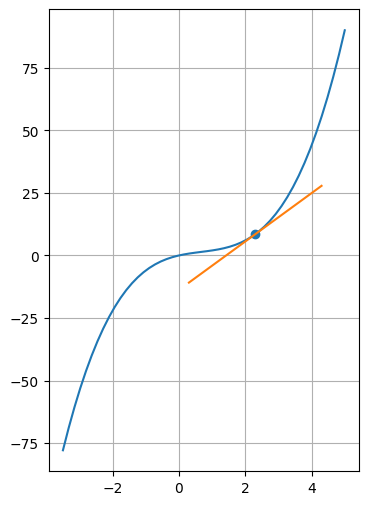

In [9]:
import matplotlib.pyplot as plt

def numerical_derivative(fn, param):    # 주어진 함수 fn에 대한 W 또는 b에 대한 수치미분
    delta = 1e-4  # 0.0001          # 실제 미분함수를 구하지 않고 특정 W, b의 +/- 0.0001 범위에서 기울기 구함
    grad = np.zeros_like(param)     # 주어진 각 W 또는 b들에 대한 기울기 값 저장

    it = np.nditer(param, flags=['multi_index'], op_flags=['readwrite'])  # 다차원 배열 원소들의 순서참조 지원 함수
    while not it.finished:
        idx = it.multi_index
        temp = param[idx]            # 주어진 W, b값(기울기 대상지점값)을 저장해두고 기울기 계산 후 다시 원상태로 되돌림

        param[idx] = temp + delta
        loss1 = fn(param).item()           # W 또는 b의 약간의 증가치(+0.0001)에 대한 손실함수 값
        param[idx] = temp - delta
        loss2 = fn(param).item()           # W 또는 b의 약간의 감소치(-0.0001)에 대한 손실함수 값

        grad[idx] = (loss1-loss2) / (2*delta)    # 주어진 W, b의 미세한 구간에서의 손실함수값의 변화량 --> 기울기

        param[idx] = temp            # 기울기값 계산시 사용된 주어진 값의 사용이 끝난뒤 원래 값으로 되돌린다.
        it.iternext()
    return grad

def f(x):
    return x**3-2*x**2+3*x

def f_prime(x) :
    return 3*x**2-4*x+3

x = np.linspace(-3.5, 5, 50)

plt.figure(figsize=(4,6))
plt.plot(x, f(x))
plt.grid(True)

x=2.3
a = numerical_derivative(f, np.array([x])) # 기울기 a는 x에서의 미분
b = f(x) - a*x      # 절편 b는 좌표 <x, f(x)>로 구함
tanLine = lambda t : a*t + b
tl = np.linspace(x-2, x+2, 20)
plt.plot(tl, tanLine(tl))
plt.scatter(x, f(x))

print("x = {}일 때의 기울기 :".format(x))
print("  수치미분 결과", a)
print("  미분함수 결과", f_prime(x))

## 손실함수 $E(W,b) $와 $W, b$의 관계

- $ E(W,b) =  \frac{1}{n} \sum (t_i - (Wx_i+b)$

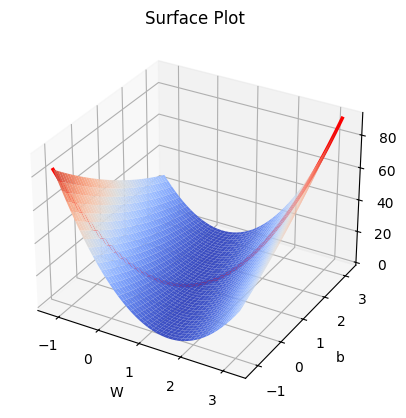

In [10]:
from mpl_toolkits.mplot3d import Axes3D

def e(W, b, x, t):     # x_date와 레이블 t_data가 주어질 때의 W, b에 대한 손실 함수
    sum = 0
    for i in range(len(x)):
        sum += (t[i]-(W*x[i]+b))**2
    return sum/len(x)

x1 = [1, 2, 3, 4, 5]
t1 = [2, 3, 4, 4, 6]

W = np.arange(-1.2, 3.3, 0.1)
b = np.arange(-1.2, 3.3, 0.1)
Wm, bm = np.meshgrid(W, b)
Z = e(Wm, bm, x1, t1)

fig = plt.figure()
# ax = fig.gca(projection="3d")  # Deprecated
    # fig = plt.figure()
    # plt.subplot(projection='3d') 도 가능함
ax = fig.add_subplot(projection='3d')
ax.plot_surface(Wm, bm, Z, cmap=plt.cm.coolwarm, linewidth=0.5)
ax.plot(W,b,e(W,b,x1,t1),color='red', linewidth=2.5)
# ax.view_init(40, -110)
plt.xlabel('W')
plt.ylabel('b')
ax.set_zlabel('E(W,b)')
plt.title("Surface Plot")
plt.show()